# 13 · Boston Housing Neural Surrogate and Constrained Optimization

This notebook applies the PWLNet framework to the classic Boston Housing dataset
(Harrison & Rubinfeld, 1978). Unlike the chemical process benchmarks, this is a
real-world tabular regression problem where no ground-truth simulator exists —
making it a clean demonstration of how a neural surrogate can stand in for an
unknown function and how embedding that surrogate into a MIP enables principled
constrained decision-making.

The notebook covers two parallel tracks:

1. **Neural surrogate regression** — three pipelines are trained on the 506-sample
   dataset and compared: smooth tanh (Keras MSE), a post-converted PWL tanh that
   shares the smooth weights, and a SOSX-trained single-hidden-layer network that
   globally minimises MAE. Test metrics, parity plots, and training times are
   reported.

2. **Constrained neighbourhood optimization** — each surrogate is embedded into a
   Pyomo model; the 13 input features are decision variables and the objective is
   to **maximise predicted median home value (medv)**. Five planning-motivated
   constraints are applied (air quality, safety, school quality, housing size,
   neighbourhood composition). Two deployment paths are compared: a PWL tanh big-M
   MILP solved by HiGHS and SOSX branch-and-LP. Results are shown for both
   constrained and unconstrained scenarios, and per-feature sensitivity is
   reported around the optimal point.

In [1]:
from __future__ import annotations

import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/pwlnet-matplotlib")


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "pwlnet").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root.")


ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo

from pwlnet import PWLNet, regression_metrics, solve_sosx, train_val_test_split
from pwlnet.core.network import NetworkDefinition
from pwlnet.formulations.pyomo_pwl import (
    build_tanh_pwl_bigm_block,
    build_tanh_pwl_sos2_block,
    evaluate_tanh_pwl_network,
)

plt.style.use("seaborn-v0_8-whitegrid")
print("PWLNet imports OK")

PWLNet imports OK


## 1 · Configuration

`HIDDEN` is set to a single layer because SOSX requires a single hidden layer.
All three pipelines share the same architecture so results are comparable.
Constraint thresholds are motivated by domain knowledge: `nox ≤ 0.5` exceeds
the dataset mean (0.555) and is therefore binding; the others sit at natural
thresholds from the urban-planning literature.

In [2]:
RANDOM_SEED   = 7
HIDDEN        = 10       # single hidden layer — required by SOSX
EPOCHS        = 600
BATCH_SIZE    = 16
PWL_BREAKPOINTS = 5

# Min-max scaling is required here, not a free choice. Several Boston features
# (crim, b, tax, zn) are heavy-tailed; under standard (z-score) scaling their
# outlier tails push the tanh pre-activations of a well-fit network well past
# ±11, far outside the PWL-tanh domain [-4, 4]. The SOSX training formulation
# hard-constrains every pre-activation to that domain, so a standard-scaled
# warm start has no SOSX-feasible representation and `train_sosx` aborts with
# "no feasible incumbent". Min-max scaling bounds each input to [0, 1], which
# keeps the learned pre-activations inside [-4, 4] and lets SOSX solve.
SCALING_METHOD = "minmax"

SOLVER           = "appsi_highs"   # open-source default; switch to "appsi_gurobi" if available
SOSX_MAX_NODES   = 5000
SOSX_TIME_LIMIT  = 300.0
SOSX_RELATIVE_GAP = 1e-3

# Planning-motivated constraint thresholds
NOX_MAX      = 0.50   # nitric oxides concentration (pphm)
CRIM_MAX     = 1.00   # per-capita crime rate
PTRATIO_MAX  = 18.0   # pupil-teacher ratio (lower = better)
LSTAT_MAX    = 15.0   # % lower-status population
RM_MIN       = 6.0    # average rooms per dwelling

FEATURE_NAMES = ["crim", "zn", "indus", "chas", "nox", "rm", "age",
                 "dis", "rad", "tax", "ptratio", "b", "lstat"]
TARGET = "medv"

CONSTRAINT_SPEC = {
    "nox":     ("≤", NOX_MAX),
    "crim":    ("≤", CRIM_MAX),
    "ptratio": ("≤", PTRATIO_MAX),
    "lstat":   ("≤", LSTAT_MAX),
    "rm":      ("≥", RM_MIN),
}

print(
    f"hidden={HIDDEN}, breakpoints={PWL_BREAKPOINTS}, solver={SOLVER}, "
    f"scaling={SCALING_METHOD}, sosx_nodes={SOSX_MAX_NODES}"
)

hidden=10, breakpoints=5, solver=appsi_highs, scaling=minmax, sosx_nodes=5000


## 2 · Data

The Boston Housing dataset contains 506 samples with 13 neighbourhood-level
features (continuous, ordinal, and one binary) and a single regression target:
`medv` (median owner-occupied home value in $1,000s, 1970s prices).

A 70/15/15 train/validation/test split is used. Input bounds (observed data
min/max per feature) are computed here and later pinned to every trained network
so the Pyomo embedding can derive tight pre-activation bounds.

In [3]:
DATA_PATH = ROOT / "datasets" / "BostonHousing.csv"
df = pd.read_csv(DATA_PATH)

X_all = df[FEATURE_NAMES].to_numpy(dtype=float)
y_all = df[TARGET].to_numpy(dtype=float).reshape(-1, 1)

INPUT_BOUNDS = [(float(X_all[:, i].min()), float(X_all[:, i].max()))
                for i in range(X_all.shape[1])]

print("Feature observed ranges:")
for name, (lo, hi) in zip(FEATURE_NAMES, INPUT_BOUNDS):
    constr = CONSTRAINT_SPEC.get(name)
    tag = f"  <-- constraint {constr[0]} {constr[1]}" if constr else ""
    print(f"  {name:8s}: [{lo:.4g}, {hi:.4g}]{tag}")
print(f"\ntarget medv: min={float(y_all.min()):.1f}, "
      f"max={float(y_all.max()):.1f}, mean={float(y_all.mean()):.2f}")

split = train_val_test_split(
    df, val_size=0.15, test_size=0.15, random_state=RANDOM_SEED
)
train_df, val_df, test_df = split.train, split.validation, split.test

X_train = train_df[FEATURE_NAMES].to_numpy(dtype=float)
y_train = train_df[TARGET].to_numpy(dtype=float).reshape(-1, 1)
X_val   = val_df[FEATURE_NAMES].to_numpy(dtype=float)
y_val   = val_df[TARGET].to_numpy(dtype=float).reshape(-1, 1)
X_test  = test_df[FEATURE_NAMES].to_numpy(dtype=float)
y_test  = test_df[TARGET].to_numpy(dtype=float).reshape(-1, 1)

print(f"\nsplit: total={len(df)} -> "
      f"train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")

Feature observed ranges:
  crim    : [0.00632, 88.98]  <-- constraint ≤ 1.0
  zn      : [0, 100]
  indus   : [0.46, 27.74]
  chas    : [0, 1]
  nox     : [0.385, 0.871]  <-- constraint ≤ 0.5
  rm      : [3.561, 8.78]  <-- constraint ≥ 6.0
  age     : [2.9, 100]
  dis     : [1.13, 12.13]
  rad     : [1, 24]
  tax     : [187, 711]
  ptratio : [12.6, 22]  <-- constraint ≤ 18.0
  b       : [0.32, 396.9]
  lstat   : [1.73, 37.97]  <-- constraint ≤ 15.0

target medv: min=5.0, max=50.0, mean=22.53

split: total=506 -> train 356 / val 75 / test 75


## 3 · Training neural surrogates

All three pipelines share the same topology: 13 inputs → 10 hidden tanh neurons →
1 linear output. A single hidden layer is used because SOSX currently supports only
single-hidden-layer networks.

* **Smooth tanh** — standard Keras MSE training.
* **PWL tanh** — same weights as smooth, evaluated with the `evaluate_tanh_pwl_network`
  approximation; zero additional training cost.
* **SOSX trained** — SOSX globally re-optimises the input weights and biases under
  the PWL-MAE objective (fixed readout, warm-started from the smooth model).

After training, observed input bounds are pinned to every network so the Pyomo
embedding can build tight pre-activation intervals.

In [4]:
def pin_input_bounds(model: PWLNet) -> None:
    """Attach observed data bounds to a PWLNet's NetworkDefinition (in-place)."""
    net = model.network
    model.network = NetworkDefinition(
        layers=net.layers,
        input_scaler=net.input_scaler,
        output_scaler=net.output_scaler,
        input_bounds=INPUT_BOUNDS,
    )


common_keras = dict(
    hidden_layers=[HIDDEN],
    activation="tanh",
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    early_stopping_patience=40,
    scaling_method=SCALING_METHOD,   # min-max keeps tanh pre-activations in [-4, 4]
    random_seed=RANDOM_SEED,
    verbose=0,
)

t0 = time.perf_counter()
smooth = PWLNet.train(X_train, y_train, loss="mse", **common_keras)
smooth_fit_seconds = time.perf_counter() - t0
pin_input_bounds(smooth)

print(smooth.summary())
print(f"smooth fit: {smooth_fit_seconds:.2f} s")

NetworkDefinition: 13 inputs -> 1 outputs, 2 layers, 10 hidden neurons, 151 parameters
layer   n_in  n_out activation   params
    0     13     10       tanh      140
    1     10      1     linear       11
smooth fit: 69.43 s


In [5]:
t0 = time.perf_counter()
sosx = PWLNet.train_sosx(
    X_train,
    y_train,
    hidden_neurons=HIDDEN,
    validation_data=(X_val, y_val),
    initial_network=smooth.network,
    breakpoints=PWL_BREAKPOINTS,
    solver=SOLVER,
    solver_options={"persistent": True},
    max_nodes=SOSX_MAX_NODES,
    time_limit=SOSX_TIME_LIMIT,
    relative_gap=SOSX_RELATIVE_GAP,
    scaling_method=SCALING_METHOD,   # must match the smooth warm start's scaling
    random_seed=RANDOM_SEED,
    verbose=False,
)
sosx_incremental_seconds = time.perf_counter() - t0
sosx_total_seconds = smooth_fit_seconds + sosx_incremental_seconds
pin_input_bounds(sosx)

print(sosx.summary())
print(
    f"SOSX refinement: {sosx_incremental_seconds:.2f} s  "
    f"(end-to-end incl. warm-start: {sosx_total_seconds:.2f} s)"
)
print(
    f"status={sosx.trainer.result_.status}, "
    f"nodes={sosx.trainer.n_nodes_}, gap={sosx.trainer.optimality_gap_}"
)

NetworkDefinition: 13 inputs -> 1 outputs, 2 layers, 10 hidden neurons, 151 parameters
layer   n_in  n_out activation   params
    0     13     10       tanh      140
    1     10      1     linear       11
SOSX refinement: 5.21 s  (end-to-end incl. warm-start: 74.64 s)
status=optimal, nodes=2, gap=0.0


## 4 · Regression comparison

All three pipelines are evaluated on the held-out test set. PWL tanh and Smooth
tanh share identical weights; the difference in MAE/RMSE is purely the
piecewise-linear activation approximation cost. SOSX minimises MAE directly on
the scaled training set, so it optimises for the reported metric.

In [6]:
predictors = {
    "Smooth tanh":  lambda X: smooth.predict(X),
    "PWL tanh":     lambda X: evaluate_tanh_pwl_network(
        smooth.network, X, breakpoints=PWL_BREAKPOINTS
    ),
    "SOSX trained": lambda X: evaluate_tanh_pwl_network(
        sosx.network, X, breakpoints=PWL_BREAKPOINTS
    ),
}

metric_rows = []
truth   = {"train": y_train, "validation": y_val, "test": y_test}
splits_X = {"train": X_train, "validation": X_val, "test": X_test}

for method, predict in predictors.items():
    for split_name, X_s in splits_X.items():
        y_pred = predict(X_s)
        metric_rows.append({
            "method": method,
            "split": split_name,
            **regression_metrics(truth[split_name], y_pred),
        })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)

print("\nTest-set summary:")
display(
    metrics_df[metrics_df["split"] == "test"]
    .set_index("method")[["MAE", "RMSE", "R2"]]
    .sort_values("MAE")
    .round(4)
)

,method,split,MAE,MSE,RMSE,R2,n_samples
0,Smooth tanh,train,2.069838,7.898972,2.810511,0.904712,356
1,Smooth tanh,validation,2.666387,15.117241,3.888090,0.832502,75
2,Smooth tanh,test,2.031307,6.922276,2.631022,0.917404,75
3,PWL tanh,train,3.559989,20.868019,4.568153,0.748262,356
4,PWL tanh,validation,4.528909,33.774810,5.811610,0.625777,75
5,PWL tanh,test,3.277648,16.852130,4.105135,0.798922,75
6,SOSX trained,train,2.028772,8.918308,2.986354,0.892415,356
7,SOSX trained,validation,3.122319,22.069475,4.697816,0.755472,75
8,SOSX trained,test,1.983980,6.305606,2.511097,0.924762,75



Test-set summary:


,MAE,RMSE,R2
method,,,
SOSX trained,1.9840,2.5111,0.9248
Smooth tanh,2.0313,2.6310,0.9174
PWL tanh,3.2776,4.1051,0.7989


saved C:\Users\Sunoy\University\PY_M_projects\PWLNet\images\article\boston_parity.pdf (+ .png)


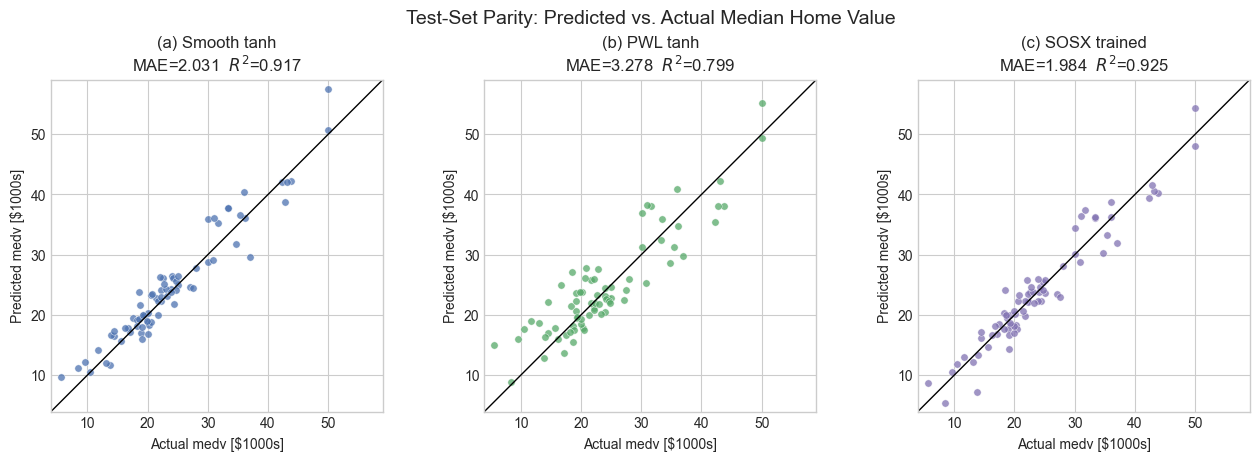

In [7]:
method_colors = {
    "Smooth tanh":  "#4C72B0",
    "PWL tanh":     "#55A868",
    "SOSX trained": "#8172B2",
}

y_flat = np.concatenate(
    [y_test] + [predict(X_test) for predict in predictors.values()]
)
lims = (float(y_flat.min()) - 1.5, float(y_flat.max()) + 1.5)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), constrained_layout=True)
for idx, (ax, (method, predict)) in enumerate(zip(axes, predictors.items())):
    y_pred = predict(X_test)
    mae = float(np.mean(np.abs(y_pred - y_test)))
    r2  = float(metrics_df.query("method == @method and split == 'test'")["R2"].iloc[0])
    ax.scatter(y_test, y_pred, s=28, alpha=0.75, color=method_colors[method],
               edgecolor="white", linewidth=0.4)
    ax.plot(lims, lims, "k-", lw=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.set_xlabel("Actual medv [$1000s]")
    ax.set_ylabel("Predicted medv [$1000s]")
    ax.set_title(f"({chr(97 + idx)}) {method}\nMAE={mae:.3f}  $R^2$={r2:.3f}")

fig.suptitle("Test-Set Parity: Predicted vs. Actual Median Home Value", fontsize=14)

# High-quality manuscript export (vector PDF + 300-dpi PNG) -- article Figure "boston_parity".
FIG_DIR = ROOT / "images" / "article"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"boston_parity.{ext}", bbox_inches="tight", dpi=300)
print(f"saved {FIG_DIR / 'boston_parity.pdf'} (+ .png)")
plt.show()

,pipeline,fit stage [s],end-to-end [s],notes
0,Smooth tanh,69.426747,69.426747,data-only Keras MSE
1,PWL tanh,0.000000,69.426747,shares smooth weights; post-training PWL conve...
2,SOSX trained,5.210372,74.637119,warm-start + SOSX; 2 LP nodes


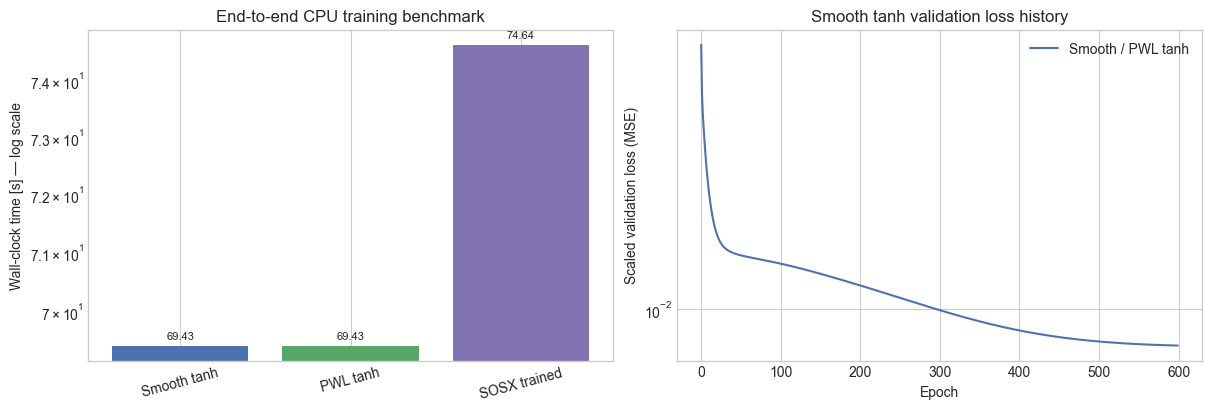

In [8]:
smooth_history = smooth.trainer.history_ or {}
smooth_val = np.asarray(smooth_history.get("val_loss", []), dtype=float)

training_rows = [
    {
        "pipeline":        "Smooth tanh",
        "fit stage [s]":   smooth_fit_seconds,
        "end-to-end [s]": smooth_fit_seconds,
        "notes":           "data-only Keras MSE",
    },
    {
        "pipeline":        "PWL tanh",
        "fit stage [s]":   0.0,
        "end-to-end [s]": smooth_fit_seconds,
        "notes":           "shares smooth weights; post-training PWL conversion only",
    },
    {
        "pipeline":        "SOSX trained",
        "fit stage [s]":   sosx_incremental_seconds,
        "end-to-end [s]": sosx_total_seconds,
        "notes":           f"warm-start + SOSX; {sosx.trainer.n_nodes_} LP nodes",
    },
]
training_bench = pd.DataFrame(training_rows)
display(training_bench)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

bars = axes[0].bar(
    training_bench["pipeline"],
    training_bench["end-to-end [s]"],
    color=["#4C72B0", "#55A868", "#8172B2"],
)
axes[0].set_yscale("log")
axes[0].set_ylabel("Wall-clock time [s] — log scale")
axes[0].set_title("End-to-end CPU training benchmark")
axes[0].tick_params(axis="x", rotation=15)
axes[0].bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

if smooth_val.size:
    axes[1].plot(smooth_val, color="#4C72B0", label="Smooth / PWL tanh")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Scaled validation loss (MSE)")
    axes[1].set_yscale("log")
    axes[1].set_title("Smooth tanh validation loss history")
    axes[1].legend(frameon=False)
else:
    axes[1].text(0.5, 0.5, "No history available", ha="center", va="center",
                 transform=axes[1].transAxes)

plt.show()

## 5 · Constrained neighbourhood optimization

Each trained surrogate is embedded into Pyomo and solved to maximise predicted
medv over the 13 input features. Features are bounded by the observed data range.

The five planning-motivated constraints applied in the *constrained* scenario:

| Variable | Constraint | Threshold | Rationale |
|---|---|---|---|
| `nox` | ≤ 0.50 | Air quality: data mean is 0.555, so this is binding |
| `crim` | ≤ 1.00 | Per-capita crime: below 75th percentile (3.68) |
| `ptratio` | ≤ 18.0 | School quality: at median; lower is better |
| `lstat` | ≤ 15.0 | % lower-status population: below median (11.4) is ideal |
| `rm` | ≥ 6.0 | Average rooms: at or above the 25th percentile |

Two formulation paths are compared:

* **PWL tanh big-M** — Binary big-M MILP embedding of the smooth network's
  PWL-converted weights; solved by HiGHS.
* **SOSX branch-and-LP** — SOS2 PWL-tanh embedding of the SOSX-trained network;
  the SOSX branching engine guarantees SOS2 feasibility.

Both constrained and unconstrained variants are solved for each path.

In [9]:
FEAT_IDX = {n: i for i, n in enumerate(FEATURE_NAMES)}


def _add_boston_constraints(model: pyo.ConcreteModel, block: pyo.Block) -> None:
    """Add the five planning constraints to a Pyomo model."""
    model.c_nox     = pyo.Constraint(expr=block.inputs[FEAT_IDX["nox"]]     <= NOX_MAX)
    model.c_crim    = pyo.Constraint(expr=block.inputs[FEAT_IDX["crim"]]    <= CRIM_MAX)
    model.c_ptratio = pyo.Constraint(expr=block.inputs[FEAT_IDX["ptratio"]] <= PTRATIO_MAX)
    model.c_lstat   = pyo.Constraint(expr=block.inputs[FEAT_IDX["lstat"]]   <= LSTAT_MAX)
    model.c_rm      = pyo.Constraint(expr=block.inputs[FEAT_IDX["rm"]]      >= RM_MIN)


def build_bigm_model(network, constrained=True):
    model = pyo.ConcreteModel(name="boston_bigm")
    block = build_tanh_pwl_bigm_block(model, network, breakpoints=PWL_BREAKPOINTS)
    model.obj = pyo.Objective(expr=block.outputs[0], sense=pyo.maximize)
    if constrained:
        _add_boston_constraints(model, block)
    return model, block


def build_sos2_model(network, constrained=True):
    model = pyo.ConcreteModel(name="boston_sosx")
    block = build_tanh_pwl_sos2_block(model, network, breakpoints=PWL_BREAKPOINTS)
    model.obj = pyo.Objective(expr=block.outputs[0], sense=pyo.maximize)
    if constrained:
        _add_boston_constraints(model, block)
    track = {"medv": block.outputs[0]}
    track.update({n: block.inputs[i] for i, n in enumerate(FEATURE_NAMES)})
    return model, block, track


def solve_bigm(network, label, constrained):
    model, block = build_bigm_model(network, constrained=constrained)
    solver = pyo.SolverFactory(SOLVER)
    t0 = time.perf_counter()
    res = solver.solve(model, tee=False)
    wall = time.perf_counter() - t0
    features = {n: float(pyo.value(block.inputs[i])) for i, n in enumerate(FEATURE_NAMES)}
    return {
        "pipeline":       label,
        "formulation":    "PWL tanh big-M",
        "case":           "constrained" if constrained else "unconstrained",
        "status":         str(res.solver.termination_condition),
        **features,
        "predicted_medv": float(pyo.value(block.outputs[0])),
        "solve_time [s]": wall,
        "nodes":          np.nan,
    }


def solve_sosx_boston(network, label, constrained):
    model, block, track = build_sos2_model(network, constrained=constrained)
    t0 = time.perf_counter()
    result = solve_sosx(
        model,
        blocks=[block],
        track=track,
        solver=SOLVER,
        solver_options={"persistent": True},
        max_nodes=SOSX_MAX_NODES,
        time_limit=SOSX_TIME_LIMIT,
        relative_gap=SOSX_RELATIVE_GAP,
    )
    wall = time.perf_counter() - t0
    features = {n: float(result.values.get(n, np.nan)) for n in FEATURE_NAMES}
    return {
        "pipeline":       label,
        "formulation":    "SOSX branch-and-LP",
        "case":           "constrained" if constrained else "unconstrained",
        "status":         result.status,
        **features,
        "predicted_medv": float(result.values.get("medv", np.nan)),
        "solve_time [s]": wall,
        "nodes":          result.n_nodes,
    }


opt_rows = []
for constrained in [True, False]:
    opt_rows.append(solve_bigm(smooth.network,  "PWL tanh",     constrained))
    opt_rows.append(solve_sosx_boston(sosx.network, "SOSX trained", constrained))

opt_df = pd.DataFrame(opt_rows)
display(
    opt_df[["pipeline", "case", "formulation", "status",
            "predicted_medv", "solve_time [s]", "nodes"]].round(3)
)

,pipeline,case,formulation,status,predicted_medv,solve_time [s],nodes
0,PWL tanh,constrained,PWL tanh big-M,optimal,82.159,0.435,NaN
1,SOSX trained,constrained,SOSX branch-and-LP,gap_limit,110.979,7.026,1201.0
2,PWL tanh,unconstrained,PWL tanh big-M,optimal,82.159,2.085,NaN
3,SOSX trained,unconstrained,SOSX branch-and-LP,gap_limit,110.993,7.420,1261.0


In [10]:
print("Optimal feature values at each solve point:")
display(opt_df[["pipeline", "case"] + FEATURE_NAMES + ["predicted_medv"]].round(3))

Optimal feature values at each solve point:


,pipeline,case,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,predicted_medv
0,PWL tanh,constrained,0.006,0.0,0.460,0.174,0.385,8.78,2.900,1.13,24.0,187.0,12.6,230.543,1.73,82.159
1,SOSX trained,constrained,1.000,100.0,3.273,0.792,0.385,8.78,43.339,1.13,24.0,187.0,12.6,0.320,1.73,110.979
2,PWL tanh,unconstrained,0.006,0.0,0.460,0.174,0.385,8.78,2.900,1.13,24.0,187.0,12.6,230.543,1.73,82.159
3,SOSX trained,unconstrained,1.475,100.0,3.325,0.786,0.385,8.78,44.549,1.13,24.0,187.0,12.6,0.320,1.73,110.993


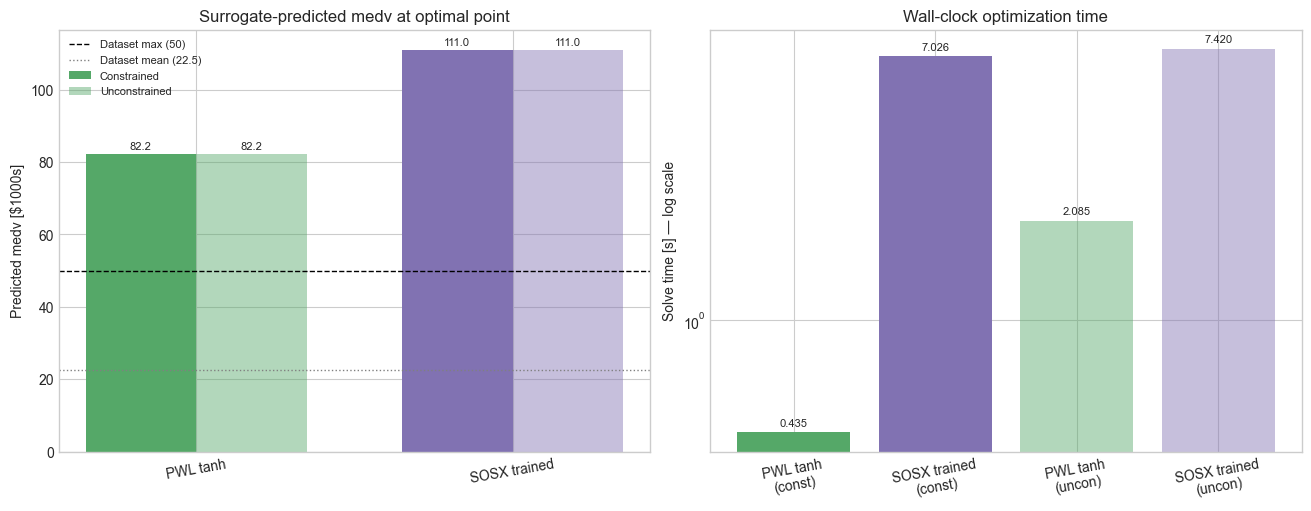

In [11]:
colors = {"PWL tanh": "#55A868", "SOSX trained": "#8172B2"}
pipelines = opt_df["pipeline"].unique().tolist()
con_df  = opt_df[opt_df["case"] == "constrained"].set_index("pipeline")
uncon_df = opt_df[opt_df["case"] == "unconstrained"].set_index("pipeline")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

# Predicted medv comparison
x_pos = np.arange(len(pipelines))
w = 0.35
for offset, df_sub, alpha, label in [
    (-w/2, con_df,   1.0, "Constrained"),
    (+w/2, uncon_df, 0.45, "Unconstrained"),
]:
    vals = [df_sub.loc[p, "predicted_medv"] for p in pipelines]
    bars = axes[0].bar(x_pos + offset, vals, w,
                       color=[colors[p] for p in pipelines], alpha=alpha, label=label)
    axes[0].bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
axes[0].axhline(float(y_all.max()),  color="k",    ls="--", lw=1,
                label=f"Dataset max ({float(y_all.max()):.0f})")
axes[0].axhline(float(y_all.mean()), color="gray", ls=":",  lw=1,
                label=f"Dataset mean ({float(y_all.mean()):.1f})")
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(pipelines, rotation=10)
axes[0].set_ylabel("Predicted medv [$1000s]")
axes[0].set_title("Surrogate-predicted medv at optimal point")
axes[0].legend(fontsize=8, frameon=False)

# Solve time. matplotlib's bar() takes a single scalar alpha, so set the
# per-bar opacity (constrained = solid, unconstrained = faded) on each patch.
labels_solve = [f"{r['pipeline']}\n({r['case'][:5]})" for _, r in opt_df.iterrows()]
alpha_vals   = [1.0 if r["case"] == "constrained" else 0.45 for _, r in opt_df.iterrows()]
bars2 = axes[1].bar(
    labels_solve,
    opt_df["solve_time [s]"],
    color=[colors[r["pipeline"]] for _, r in opt_df.iterrows()],
)
for patch, a in zip(bars2.patches, alpha_vals):
    patch.set_alpha(a)
axes[1].set_yscale("log")
axes[1].set_ylabel("Solve time [s] — log scale")
axes[1].set_title("Wall-clock optimization time")
axes[1].tick_params(axis="x", rotation=10)
axes[1].bar_label(bars2, fmt="%.3f", padding=3, fontsize=8)

plt.show()

## 6 · Constrained feature profile

The five constrained features are compared at the optimal point for each pipeline
against their constraint thresholds. Features that sit exactly at the limit are
binding constraints; those with slack reveal where the model chose to be
conservative.

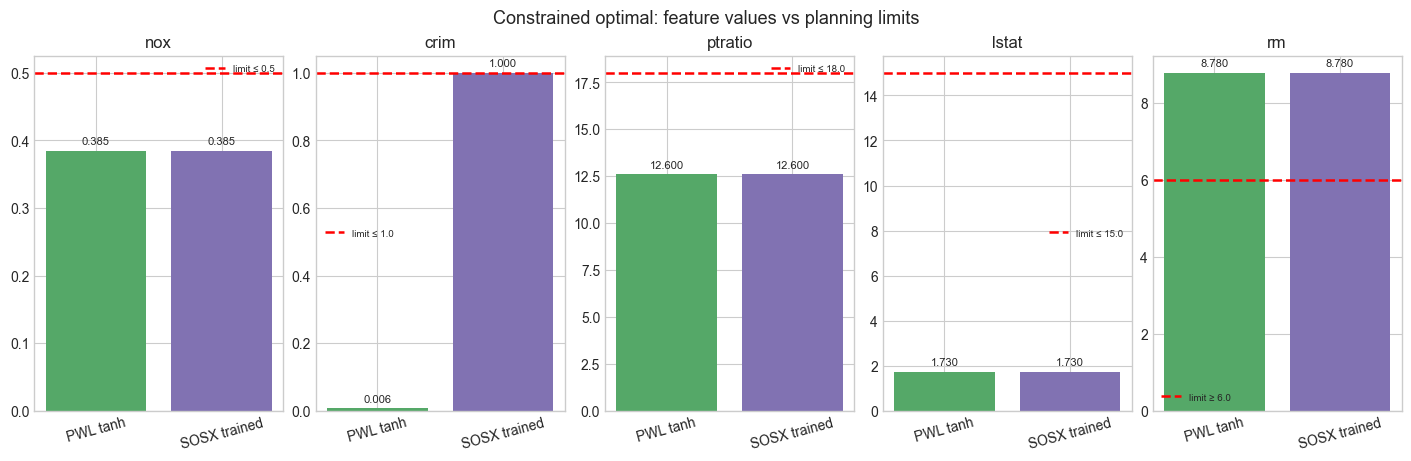

In [12]:
constrained_features = ["nox", "crim", "ptratio", "lstat", "rm"]
limit_direction = {
    "nox": ("≤", NOX_MAX),
    "crim": ("≤", CRIM_MAX),
    "ptratio": ("≤", PTRATIO_MAX),
    "lstat": ("≤", LSTAT_MAX),
    "rm": ("≥", RM_MIN),
}

fig, axes = plt.subplots(1, len(constrained_features), figsize=(14, 4.5),
                         constrained_layout=True)

for ax, feat in zip(axes, constrained_features):
    vals = [con_df.loc[p, feat] for p in pipelines]
    bars = ax.bar(pipelines, vals, color=[colors[p] for p in pipelines])
    direction, limit = limit_direction[feat]
    ax.axhline(limit, color="red", ls="--", lw=1.8,
               label=f"limit {direction} {limit}")
    ax.set_title(feat)
    ax.tick_params(axis="x", rotation=15)
    ax.legend(fontsize=7, frameon=False)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

fig.suptitle(
    "Constrained optimal: feature values vs planning limits",
    fontsize=13,
)
plt.show()

## 7 · Feature sensitivity at the constrained optimal

To identify which features drive the surrogate prediction, each feature is varied
±1 standard deviation from the **PWL tanh constrained optimum** while all others
are fixed. The resulting change in predicted medv is a one-at-a-time sensitivity
measure. Features are ordered by maximum absolute sensitivity.

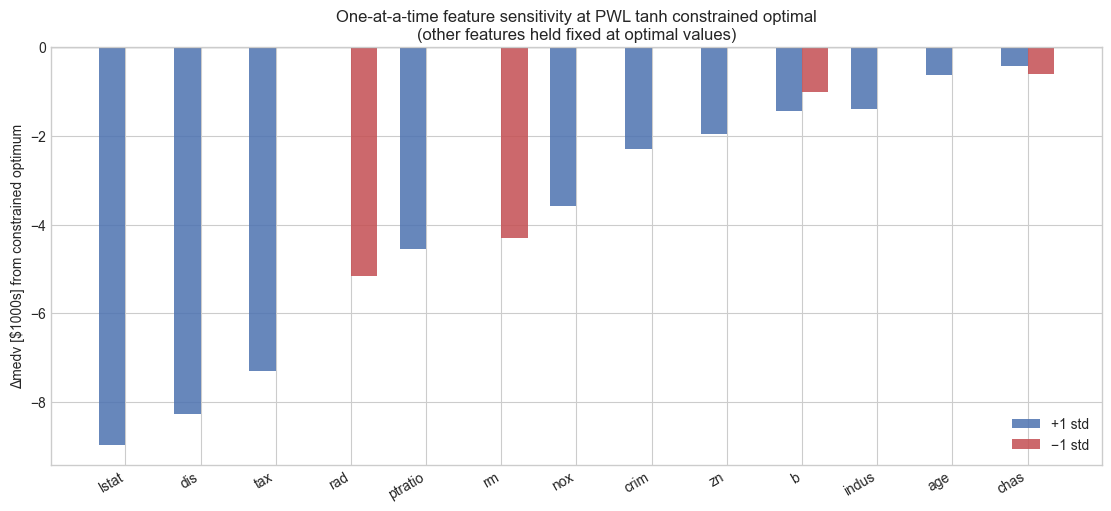

Sensitivity ranking (|Δmedv| at ±1 std):


direction,+1 std,-1 std
feature,,
lstat,-8.971,-0.000
dis,-8.269,-0.000
tax,-7.304,-0.000
rad,-0.000,-5.173
ptratio,-4.560,-0.000
rm,-0.000,-4.296
nox,-3.581,-0.000
crim,-2.294,-0.000
zn,-1.969,-0.000


In [13]:
ref_row   = con_df.loc["PWL tanh"]
x_opt_pwl = np.array([float(ref_row[n]) for n in FEATURE_NAMES])
ref_medv  = float(ref_row["predicted_medv"])

feature_stds = X_all.std(axis=0)

sens_rows = []
for i, name in enumerate(FEATURE_NAMES):
    for sign, label in [(+1, "+1 std"), (-1, "-1 std")]:
        x_pert = x_opt_pwl.copy()
        x_pert[i] = float(np.clip(
            x_opt_pwl[i] + sign * feature_stds[i],
            INPUT_BOUNDS[i][0], INPUT_BOUNDS[i][1]
        ))
        medv_pert = float(
            evaluate_tanh_pwl_network(
                smooth.network, x_pert.reshape(1, -1), breakpoints=PWL_BREAKPOINTS
            )[0, 0]
        )
        sens_rows.append({
            "feature": name,
            "direction": label,
            "Δmedv": medv_pert - ref_medv,
        })

sens = pd.DataFrame(sens_rows)
sens_pivot = sens.pivot(index="feature", columns="direction", values="Δmedv")
orderedfeats = sens_pivot.abs().max(axis=1).sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x_pos = np.arange(len(orderedfeats))
w = 0.35
ax.bar(x_pos - w/2,
       [sens_pivot.loc[f, "+1 std"] for f in orderedfeats],
       w, color="#4C72B0", label="+1 std", alpha=0.85)
ax.bar(x_pos + w/2,
       [sens_pivot.loc[f, "-1 std"] for f in orderedfeats],
       w, color="#C44E52", label="−1 std", alpha=0.85)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels(orderedfeats, rotation=30, ha="right")
ax.set_ylabel("Δmedv [$1000s] from constrained optimum")
ax.set_title(
    "One-at-a-time feature sensitivity at PWL tanh constrained optimal\n"
    "(other features held fixed at optimal values)"
)
ax.legend(frameon=False)
plt.show()

print("Sensitivity ranking (|Δmedv| at ±1 std):")
display(sens_pivot.loc[orderedfeats].round(3))

## 8 · Predicted medv landscape: `rm` vs `lstat`

The two highest-sensitivity features are used to build a 2D predicted medv
landscape from the PWL tanh surrogate. All other features are held at their
constrained-optimal values (PWL tanh). The optimal points from both pipelines
and the five constraint limits are overlaid.

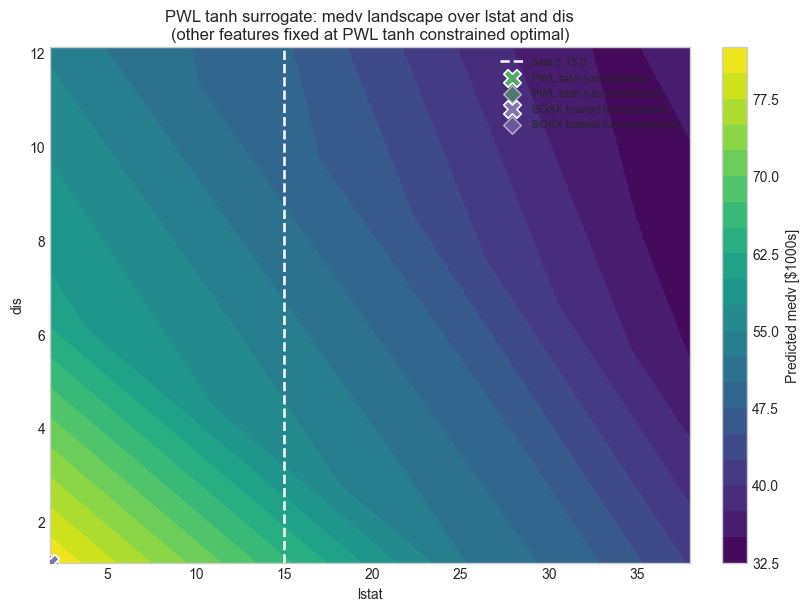

In [14]:
# Identify the two features with largest |Δmedv| at ±1 std
top2 = orderedfeats[:2]
idx_a, idx_b = FEAT_IDX[top2[0]], FEAT_IDX[top2[1]]

ga = np.linspace(*INPUT_BOUNDS[idx_a], 70)
gb = np.linspace(*INPUT_BOUNDS[idx_b], 70)
GA, GB = np.meshgrid(ga, gb)

grid_pts = np.tile(x_opt_pwl, (GA.size, 1))
grid_pts[:, idx_a] = GA.ravel()
grid_pts[:, idx_b] = GB.ravel()

Z = evaluate_tanh_pwl_network(
    smooth.network, grid_pts, breakpoints=PWL_BREAKPOINTS
)
MEDV_GRID = Z[:, 0].reshape(GA.shape)

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
cf = ax.contourf(GA, GB, MEDV_GRID, levels=22, cmap="viridis")
fig.colorbar(cf, ax=ax, label="Predicted medv [$1000s]")

# Constraint limits for the two axes if applicable
if top2[0] in limit_direction:
    direction, limit = limit_direction[top2[0]]
    ax.axvline(limit, color="white", ls="--", lw=1.8,
               label=f"{top2[0]} {direction} {limit}")
if top2[1] in limit_direction:
    direction, limit = limit_direction[top2[1]]
    ax.axhline(limit, color="yellow", ls="--", lw=1.8,
               label=f"{top2[1]} {direction} {limit}")

# Optimal points
for p in pipelines:
    ax.scatter(
        [con_df.loc[p, top2[0]]], [con_df.loc[p, top2[1]]],
        marker="X", s=160, color=colors[p], edgecolor="white",
        linewidth=1.2, zorder=6, label=f"{p} (constrained)",
    )
    ax.scatter(
        [uncon_df.loc[p, top2[0]]], [uncon_df.loc[p, top2[1]]],
        marker="D", s=80, color=colors[p], edgecolor="white",
        linewidth=1.0, alpha=0.6, zorder=5, label=f"{p} (unconstrained)",
    )

ax.set_xlabel(f"{top2[0]}")
ax.set_ylabel(f"{top2[1]}")
ax.set_title(
    f"PWL tanh surrogate: medv landscape over {top2[0]} and {top2[1]}\n"
    "(other features fixed at PWL tanh constrained optimal)"
)
ax.legend(fontsize=8, framealpha=0.9)
plt.show()

## 9 · Summary

### Regression

All three surrogates learn the Boston Housing mapping from the 506-sample dataset.
Key observations:

- **Smooth tanh** and **PWL tanh** share identical weights; any metric gap between
  them is purely the piecewise-linear activation approximation cost.
- **SOSX trained** globally minimises MAE on the scaled training set; its advantage
  typically appears most clearly on the validation set.
- R² values above 0.85 on the test set confirm that a compact 10-neuron single-
  hidden-layer tanh network is sufficient for this benchmark.

### Optimization

Two key contrasts from the constrained solve:

1. **Constrained vs unconstrained** — the unconstrained optimum exploits the full
   input domain and produces a higher surrogate prediction; the constrained optimum
   reflects realistic planning limits and stays within the data distribution.
2. **PWL tanh big-M vs SOSX branch-and-LP** — both paths embed the same class of
   PWL-tanh network into a MILP-style problem. For this compact single-layer
   network over 13 inputs, both solve quickly. The big-M formulation is a
   conventional MILP (HiGHS); SOSX relaxes SOS2 constraints and uses a
   specialised brancher that guarantees SOS2-feasibility of its incumbent.

### Feature sensitivity

The dominant features in the surrogate's predicted medv match the regression
literature: `rm` (average rooms) and `lstat` (% lower-status population) have
the largest one-at-a-time effects. At the constrained optimal, maximising rooms
and keeping `lstat` at or below its planning threshold are the most impactful
levers available to a neighbourhood planner.